这次使用的 8 个特定 coherence：
[-0.5    -0.25   -0.125  -0.0625  0.0625  0.125   0.25    0.5   ]


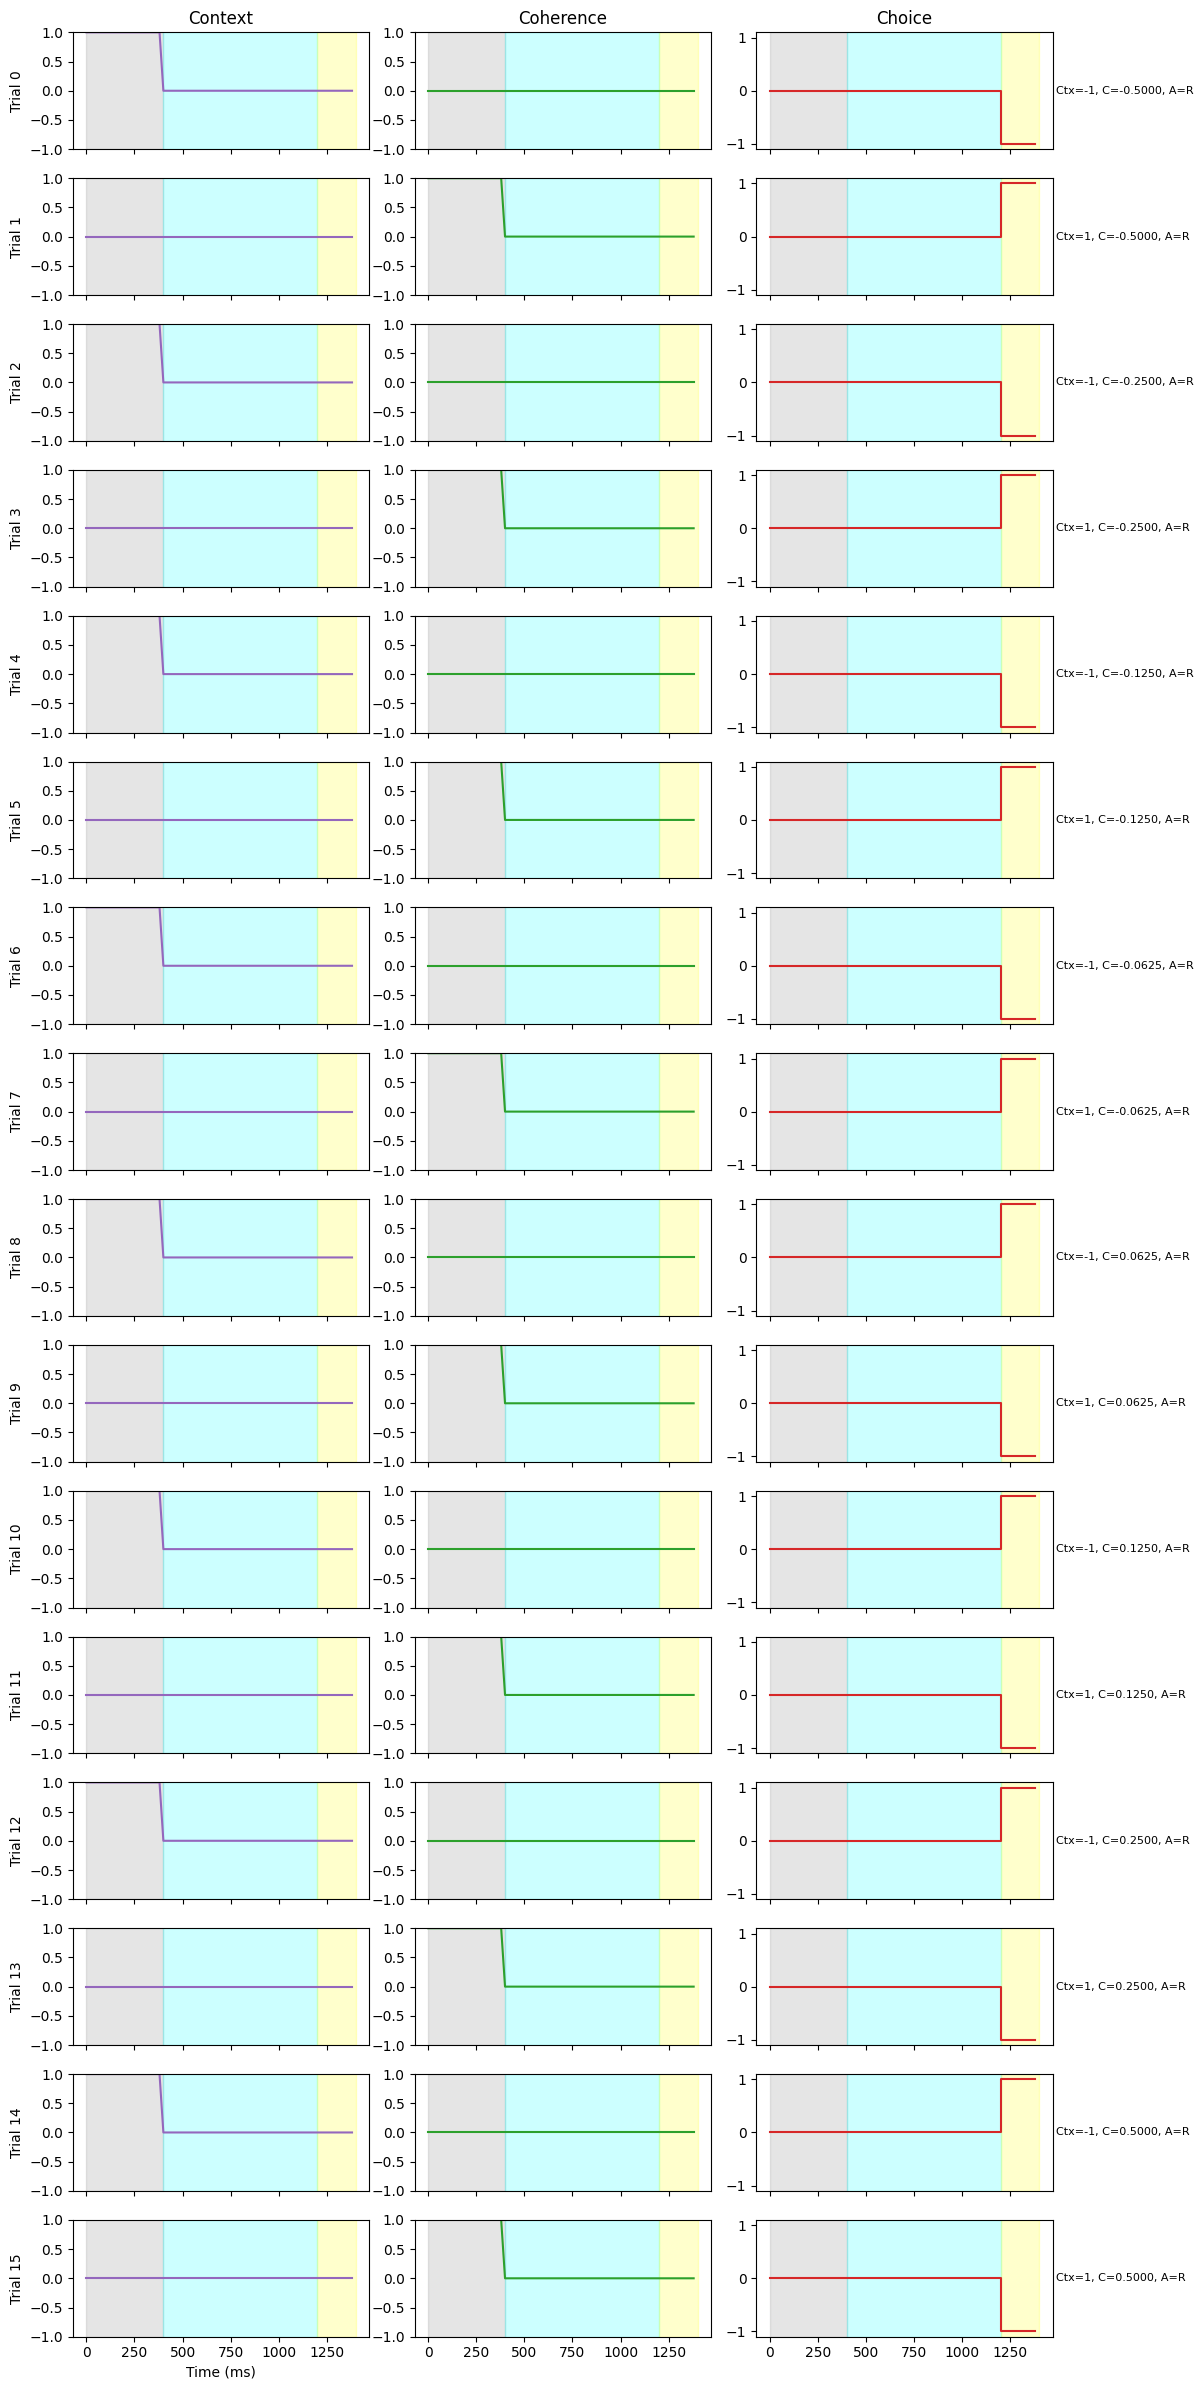

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from math import floor

# -----------------------------------------------------------------------------------
# 一、基础常量定义（与原脚本一致）
# -----------------------------------------------------------------------------------
deltaT = 20.0
t_ctx   = 400    # context cue duration (ms)
t_stim  = 800    # checkerboard stimulus duration (ms)
t_dec   = 200    # decision window (ms)
t_delay = 0      # no delay between stim and decision for simplicity

t_ctx_steps  = floor(t_ctx   / deltaT)
t_stim_steps = floor(t_stim  / deltaT)
t_dec_steps  = floor(t_dec   / deltaT)
t_total      = t_ctx_steps + t_stim_steps + t_dec_steps



# 二、生成符合 psychometric 曲线“近 0 附近密集，按 ratio=1/2” 的 8 个 coherence 值



# 在正半轴先生成 4 个几何级数（最大 0.5，ratio=1/2）
pos_vals = 0.5 * (0.5 ** np.arange(0, 4, dtype=float))  
#     pos_vals = [0.5, 0.25, 0.125, 0.0625]

# 对称取负值，并与正值拼接，得到 8 个值
neg_vals = -pos_vals[::-1]  # 先把 pos_vals 反过来再加负号 => [-0.5, -0.25, -0.125, -0.0625]
coherences = np.sort(np.concatenate([neg_vals, pos_vals])  )
#     coherences = [-0.5, -0.25, -0.125, -0.0625, 0.0625, 0.125, 0.25, 0.5]

print("这次使用的 8 个特定 coherence：")
print(coherences)
# 输出应为：
# 这次使用的 8 个特定 coherence：
# [-0.5    -0.25   -0.125  -0.0625  0.0625  0.125   0.25    0.5   ]



# 三、make_single_xor_trial：

def make_single_xor_trial(context, coherence, std=0, coh_noise_std=0):#idealized
    '''
    context: 0 或 1（目标配置）
    coherence: float，在 [-1,1] 之间
    std: 对所有通道的感官噪声强度
    coh_noise_std: 刺激阶段额外加到 coherence 通道上的噪声
    返回：
      x: Tensor(1, t_total, 3)  输入信号（第一维是 context 通道，第二维是 color coherence 通道）
      y: Tensor(1, t_total, 1)  模拟的行为序列（决策期间填入 action）
      mask: Tensor(1, t_total, 1)  0/1 矩阵，标记只有决策期间才有效
    '''
    # 1) 基础感官噪声
    x = std * torch.randn(1, t_total, 3)
    if context == -1:
        x[0, :t_ctx_steps, 0] = 1
        x[0, :t_ctx_steps, 1] = 0 
    else:
        x[0, :t_ctx_steps, 0] = 0
        x[0, :t_ctx_steps, 1] = 1

    
    # 3) 在刺激阶段（t_ctx_steps ~ t_ctx_steps + t_stim_steps）把 coherence 放到通道 1
    stim_slice = slice(t_ctx_steps, t_ctx_steps + t_stim_steps)
    x[0, stim_slice, 2] = coherence
    
    x[0, stim_slice, 2] += coh_noise_std * torch.randn(t_stim_steps)

    # color_choice: 1 if coherence > 0 else 0
    color_choice = 1 if coherence > 0 else 0

    # 新 action 规则
    if (context == 1 and color_choice == 1) or (context == -1 and color_choice == 0):
        action = -1
    else:
        action = 1

    # 5) 构造标签 y 以及有效 mask：仅在决策窗口（t_ctx+ t_stim ~ t_ctx + t_stim + t_dec）里输出 action
    y = torch.zeros(1, t_total, 1)
    mask = torch.zeros_like(y)
    start = t_ctx_steps + t_stim_steps
    y[0, start:start + t_dec_steps, 0]   = float(action)
    mask[0, start:start + t_dec_steps, 0] = 1.0

    return x, y, mask

def generate_xor_batch(n_trials, std=0.05):
    X = torch.zeros(n_trials, t_total, 3)
    Y = torch.zeros(n_trials, t_total, 1)
    M = torch.zeros_like(Y)
    params = []
    for i in range(n_trials):
        ctx = np.random.choice([-1,1])
        coh = float(np.random.choice(coherences))
        x, y, m = make_single_xor_trial(ctx, coh, std)
        X[i], Y[i], M[i] = x, y, m
        params.append((ctx, coh, int(y[0,-1,0])))
    return X, Y, M, params

# 四、可视化函数 plot_multiple_xor：一次性把若干条 trial 画到一个图里


def plot_multiple_xor(X, Y, params, trial_indices, deltaT,
                      t_ctx_steps, t_stim_steps, t_total):
    """
    一次在一个 figure 里展示多条 trial。
    - X: [N, t_total, 2] 输入张量
    - Y: [N, t_total, 1] 输出张量
    - params: 列表，长度 N，每项是 (ctx, coh, action)
    - trial_indices: 要展示的 trial 索引列表
    - deltaT: 时间步长（ms）
    - t_ctx_steps, t_stim_steps, t_total: 同上常数
    """
    n = len(trial_indices)
    fig, axes = plt.subplots(n, 3, figsize=(12, n * 1.5), sharex=True)
    t = np.arange(t_total) * deltaT

    # 定义三个阶段对应的阴影区间：Context / Stimulus / Decision
    phases = [
        ('Context', 0, t_ctx_steps, 'gray'),
        ('Stimulus', t_ctx_steps, t_ctx_steps + t_stim_steps, 'cyan'),
        ('Decision', t_ctx_steps + t_stim_steps, t_total, 'yellow')
    ]

    for row, idx in enumerate(trial_indices):
        ctx, coh, action = params[idx]
        ax_ctx, ax_coh, ax_act = axes[row]

        # ─── Context 通道 ───
        ax_ctx.plot(t, X[idx, :, 0].numpy(), color='tab:purple')
        ax_ctx.set_ylim(-1, 1)
        if row == 0:
            ax_ctx.set_title('Context')

        # ─── Coherence 通道 ───
        ax_coh.plot(t, X[idx, :, 1].numpy(), color='tab:green')
        ax_coh.set_ylim(-1, 1)
        if row == 0:
            ax_coh.set_title('Coherence')

        # ─── Action（Choice）通道 ───
        ax_act.step(t, Y[idx, :, 0].numpy(), where='post', color='tab:red')
        ax_act.set_ylim(-1.1, 1.1)
        if row == 0:
            ax_act.set_title('Choice')

        # 对三个子图都加阴影，标记出 Context / Stimulus / Decision 三个时段
        for ax in (ax_ctx, ax_coh, ax_act):
            for name, start, end, color in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=color, alpha=0.2)

        # 只在每行的第一列加 y 轴标签“Trial idx”
        axes[row, 0].set_ylabel(f'Trial {idx}')
        # 在第三列右侧用 annotate 标注当前 trial 的参数信息
        axes[row, 2].annotate(
            f'Ctx={ctx}, C={coh:.4f}, A={"R" if action else "L"}',
            xy=(1.01, 0.5), xycoords='axes fraction',
            va='center', fontsize=8
        )

    # x 轴标签只放在最底下一行
    axes[-1, 0].set_xlabel('Time (ms)')
    plt.tight_layout()
    plt.show()


# 
# 专门选取 8 个 coherence × 2 个 context，共 16 条 trial，并一次性可视化

if __name__ == '__main__':
    # 1）预先分配容器，用于存放 16 条选定的 trial
    n_sel = len(coherences) * 2  # 8 个 coherence × 2 个 context = 16
    X_sel = torch.zeros(n_sel, t_total, 3)
    Y_sel = torch.zeros(n_sel, t_total, 1)
    M_sel = torch.zeros_like(Y_sel)
    params_sel = []   # 用来存 (ctx, coh, action)

    # 2）按顺序：先对每个 coherence，在 context=0 下生一 trial；再同样对同一个 coherence 在 context=1 下生一 trial
    idx = 0
    for coh in coherences:
        for ctx in [-1, 1]:
            x, y, m = make_single_xor_trial(ctx, float(coh))
            X_sel[idx] = x
            Y_sel[idx] = y
            M_sel[idx] = m
            # y[0, -1, 0]＝最后时刻（决策结束时）的 action 值
            params_sel.append((ctx, float(coh), int(y[0, -1, 0])))  
            idx += 1

    # 3）调用 plot_multiple_xor，一次性展示 16 条 trial
    #    trial_indices 直接用 [0, 1, …, 15]
    all_indices = list(range(n_sel))  # [0,1,2,...,15]
    plot_multiple_xor(X_sel, Y_sel, params_sel, all_indices,
        deltaT, t_ctx_steps, t_stim_steps, t_total)
    


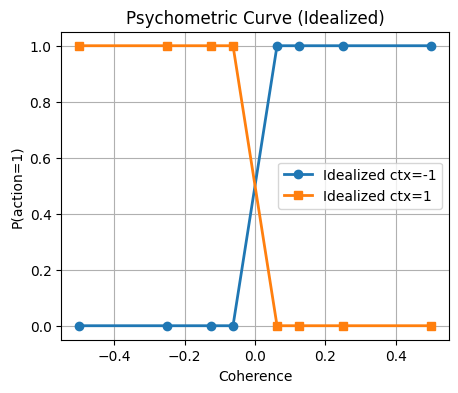

In [2]:
cohs = np.array(coherences)
probs_ctx_neg1 = []
probs_ctx1 = []

for coh in cohs:
    # ctx=-1
    idxs0 = [i for i, p in enumerate(params_sel) if abs(p[1] - coh) < 1e-8 and p[0] == -1]
    if len(idxs0) == 0:
        probs_ctx_neg1.append(np.nan)
    else:
        y_last0 = [Y_sel[i, -1, 0].item() for i in idxs0]
        probs_ctx_neg1.append(np.mean(np.array(y_last0) > 0.5))
    # ctx=1
    idxs1 = [i for i, p in enumerate(params_sel) if abs(p[1] - coh) < 1e-8 and p[0] == 1]
    if len(idxs1) == 0:
        probs_ctx1.append(np.nan)
    else:
        y_last1 = [Y_sel[i, -1, 0].item() for i in idxs1]
        probs_ctx1.append(np.mean(np.array(y_last1) > 0.5))

cohs = np.sort(np.array(coherences))
plt.figure(figsize=(5,4))
plt.plot(cohs, probs_ctx_neg1, 'o-', lw=2, label='Idealized ctx=-1')
plt.plot(cohs, probs_ctx1, 's-', lw=2, label='Idealized ctx=1')
plt.xlabel('Coherence')
plt.ylabel('P(action=1)')
plt.title('Psychometric Curve (Idealized)')
plt.legend()
plt.grid(True)
plt.show()

Training...
initial loss: 0.999
epoch 0:  loss=0.749  (took 0.43 s) *
tensor([ 1.0000,  0.0000, -0.0223]) input.....
tensor([1.]) target.....
tensor([[0.1588],
        [0.1492],
        [0.1421],
        [0.1347],
        [0.1332]], grad_fn=<SliceBackward0>) output.....
epoch 1:  loss=0.225  (took 0.43 s) *
tensor([ 1.0000,  0.0000, -0.0347]) input.....
tensor([-1.]) target.....
tensor([[-0.9661],
        [-0.9570],
        [-0.9452],
        [-0.9360],
        [-0.9177]], grad_fn=<SliceBackward0>) output.....
epoch 2:  loss=0.139  (took 0.43 s) *
tensor([ 0.0000,  1.0000, -0.0405]) input.....
tensor([-1.]) target.....
tensor([[-1.3422],
        [-1.3405],
        [-1.3406],
        [-1.3274],
        [-1.3190]], grad_fn=<SliceBackward0>) output.....
epoch 3:  loss=0.174  (took 0.43 s)
tensor([ 0.0000,  1.0000, -0.0133]) input.....
tensor([1.]) target.....
tensor([[1.0604],
        [1.0663],
        [1.0764],
        [1.0848],
        [1.0926]], grad_fn=<SliceBackward0>) output.....
ep

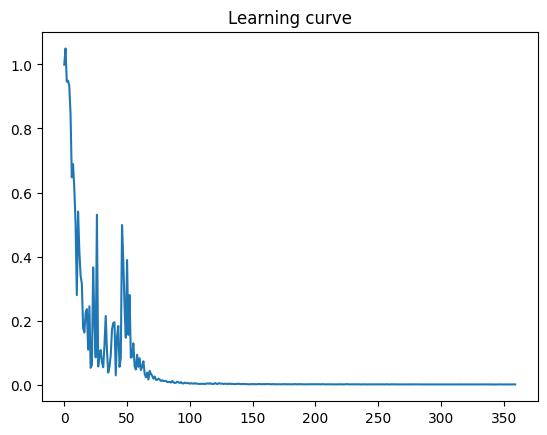

RECURRENT WEIGHT MATRIX:
Parameter containing:
tensor([[ 0.0662, -0.0192, -0.0626,  ..., -0.0011, -0.0045,  0.0049],
        [ 0.0267,  0.0483, -0.0384,  ...,  0.0357, -0.0442, -0.0259],
        [ 0.0305,  0.0267,  0.0684,  ..., -0.0352,  0.0599, -0.0040],
        ...,
        [-0.0462,  0.0076,  0.0464,  ..., -0.0955,  0.0616, -0.0365],
        [ 0.0847,  0.0689,  0.0249,  ...,  0.0080,  0.0514,  0.0390],
        [ 0.0066, -0.0298,  0.0534,  ...,  0.0005, -0.0156,  0.0463]],
       requires_grad=True)
Validation Loss: 0.0003, Accuracy: 1.0000


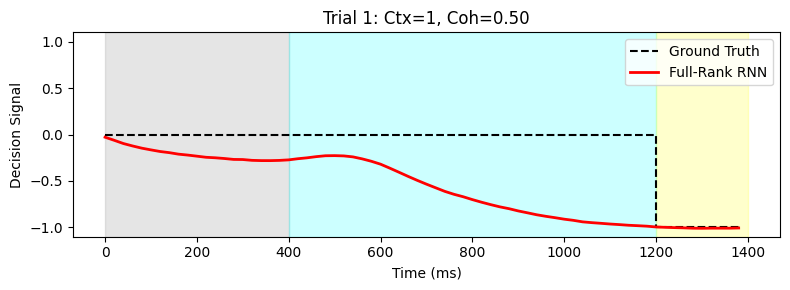

In [3]:
# 4. Training a Full-Rank RNN on the XOR Task
%load_ext autoreload
%autoreload 2

import sys
sys.path.append(r'C:\Users\13911\Desktop') 
import torch
import numpy as np
import matplotlib.pyplot as plt
from FullRank import FullRankRNN, loss_mse, train, accuracy_general
from low_rank_rnns.helpers import map_device
from math import floor
# —— 任务 & 数据准备（同之前）
deltaT = 20.
t_ctx     = 400
t_stim    = 800
t_dec     = 200
t_ctx_steps  = floor(t_ctx/deltaT)
t_stim_steps = floor(t_stim/deltaT)
t_dec_steps  = floor(t_dec/deltaT)
t_total      = t_ctx_steps + t_stim_steps + t_dec_steps


# 4.1 超参数
INPUT_SIZE  = 3      # context + coherence
HIDDEN_SIZE = 512    # 512 个隐藏单元
OUTPUT_SIZE = 1      # 标量读出
NOISE_STD   = 0.02   # recurrent 噪声
ALPHA       = 0.1    # dt/tau

# 4.2 Instantiate 全秩网络
net = FullRankRNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    output_size=OUTPUT_SIZE,
    noise_std=NOISE_STD,
    alpha=ALPHA,
    # FullRankRNN 不需要 rank 参数
    train_wi=True,
    train_wo=True,
    train_wrec=True,
    train_h0=False,
)

# 4.3 生成 & 划分数据
X_all, Y_all, M_all, params_all = generate_xor_batch(n_trials=500, std=0.05)
split = int(0.8 * X_all.shape[0])
X_tr, X_val = X_all[:split], X_all[split:]
Y_tr, Y_val = Y_all[:split], Y_all[split:]
M_tr, M_val = M_all[:split], M_all[split:]

# 4.4 移动到 GPU/CPU
X_tr, Y_tr, M_tr, X_val, Y_val, M_val = map_device(
    [X_tr, Y_tr, M_tr, X_val, Y_val, M_val], net
)

# 4.5 训练函数封装
def run_training():
    train(
        net,
        X_tr, Y_tr, M_tr,
        n_epochs=30,
        lr=1e-3,#1e-3,
        batch_size=32,#128,
        plot_learning_curve=True,
        plot_gradient=False,
        cuda=torch.cuda.is_available(),
        keep_best=True,
    )
    # 验证集评估
    with torch.no_grad():
        out = net(X_val)
        val_loss = loss_mse(out, Y_val, M_val).item()
        val_acc  = accuracy_general(out, Y_val, M_val).item()
        print(f"Validation Loss: {val_loss:.4f}, Accuracy: {val_acc:.4f}")

# 4.6 运行训练
if __name__ == '__main__':
    run_training()

# 4.7 单 trial 可视化
net.eval()
trial_idx = 1
ctx, coh, _ = params_all[split + trial_idx]
x, y_true, _ = make_single_xor_trial(ctx, 0.5)
with torch.no_grad():
    y_pred = net(x)[0, :, 0].cpu().numpy()
    y_true = y_true[0, :, 0].numpy()
t = np.arange(t_total) * deltaT

plt.figure(figsize=(8,3))
plt.step(t, y_true, where='post', label='Ground Truth', ls='--', c='k')
plt.plot(t, y_pred, label='Full-Rank RNN', c='r', lw=2)
for name, s, e, color in [
    ('Ctx', 0, t_ctx_steps, 'gray'),
    ('Stim', t_ctx_steps, t_ctx_steps+t_stim_steps, 'cyan'),
    ('Dec', t_ctx_steps+t_stim_steps, t_total, 'yellow'),
]:
    plt.axvspan(s*deltaT, e*deltaT, color=color, alpha=0.2)
plt.xlabel('Time (ms)')
plt.ylabel('Decision Signal')
plt.ylim(-1.1, 1.1)
plt.legend(loc='upper right')
plt.title(f'Trial {trial_idx}: Ctx={ctx}, Coh={coh:.2f}')
plt.tight_layout()
plt.show()


In [4]:
wrec = net.wrec.detach().cpu().numpy()
wi_full = net.wi_full.detach().cpu().numpy()
wo_full = net.wo_full.detach().cpu().numpy()
print("Recurrent weight matrix (wrec):")
print(wrec.shape)
print(wi_full.shape)
print(wo_full.shape)


Recurrent weight matrix (wrec):
(512, 512)
(3, 512)
(512, 1)


In [5]:
x.shape# Extract parameters from the trained network
W_rec = net.wrec.detach().cpu().numpy()
W_in  = net.wi_full.detach().cpu().numpy()
W_out = net.wo_full.detach().cpu().numpy()
alpha = net.alpha
noise_std = net.noise_std
nonlinearity = np.tanh 

def simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x_seq, h0=None, noise_std=0.0):
    """
    Simulate the RNN dynamics in numpy for analysis.
    x_seq: shape (T, input_dim)
    h0: initial hidden state, shape (hidden_dim,)
    Returns: h_seq (T, hidden_dim), r_seq (T, hidden_dim), y_seq (T, output_dim)
    """
    T, input_dim = x_seq.shape
    hidden_dim = W_rec.shape[0]
    output_dim = W_out.shape[1]
    h_seq = np.zeros((T, hidden_dim))
    r_seq = np.zeros((T, hidden_dim))
    y_seq = np.zeros((T, output_dim))
    h = np.zeros(hidden_dim) if h0 is None else h0.copy()
    r = nonlinearity(h)  # Initial state with nonlinearity applied
    for t in range(T):
        noise = np.random.randn(hidden_dim) * noise_std
        h = h + noise + alpha * (-h + r @ W_rec.T + x_seq[t] @ W_in)
        r = nonlinearity(h)  # Apply nonlinearity after noise addition
        y = r @ W_out
        h_seq[t] = h
        r_seq[t] = r
        y_seq[t] = y
    return h_seq, r_seq, y_seq
trial_idx = 1
ctx, coh, _ = params_all[split + trial_idx]
x, y_true, _ = make_single_xor_trial(1, -0.5)
h_seq, r_seq, y_seq = simulate_rnn_dynamics(
    W_rec, W_in, W_out, alpha, nonlinearity,
    x_seq=x[0].cpu().numpy(), h0=None, noise_std=noise_std
)

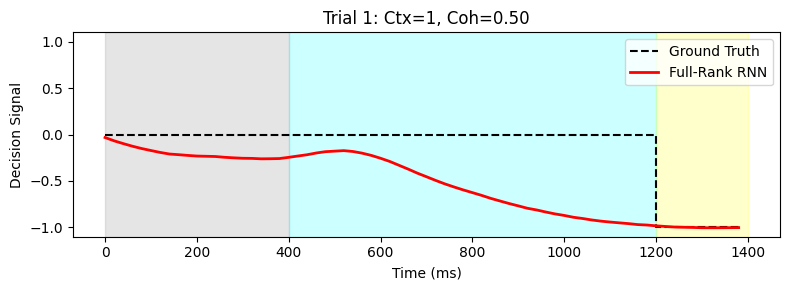

In [6]:
# 4.7 单 trial 可视化
net.eval()
trial_idx = 1
ctx, coh, _ = params_all[split + trial_idx]
x, y_true, _ = make_single_xor_trial(ctx, 0.5)
with torch.no_grad():
    y_pred = net(x)[0, :, 0].cpu().numpy()
    y_true = y_true[0, :, 0].numpy()
t = np.arange(t_total) * deltaT

plt.figure(figsize=(8,3))
plt.step(t, y_true, where='post', label='Ground Truth', ls='--', c='k')
plt.plot(t, y_pred, label='Full-Rank RNN', c='r', lw=2)
for name, s, e, color in [
    ('Ctx', 0, t_ctx_steps, 'gray'),
    ('Stim', t_ctx_steps, t_ctx_steps+t_stim_steps, 'cyan'),
    ('Dec', t_ctx_steps+t_stim_steps, t_total, 'yellow'),
]:
    plt.axvspan(s*deltaT, e*deltaT, color=color, alpha=0.2)
plt.xlabel('Time (ms)')
plt.ylabel('Decision Signal')
plt.ylim(-1.1, 1.1)
plt.legend(loc='upper right')
plt.title(f'Trial {trial_idx}: Ctx={ctx}, Coh={coh:.2f}')
plt.tight_layout()
plt.show()

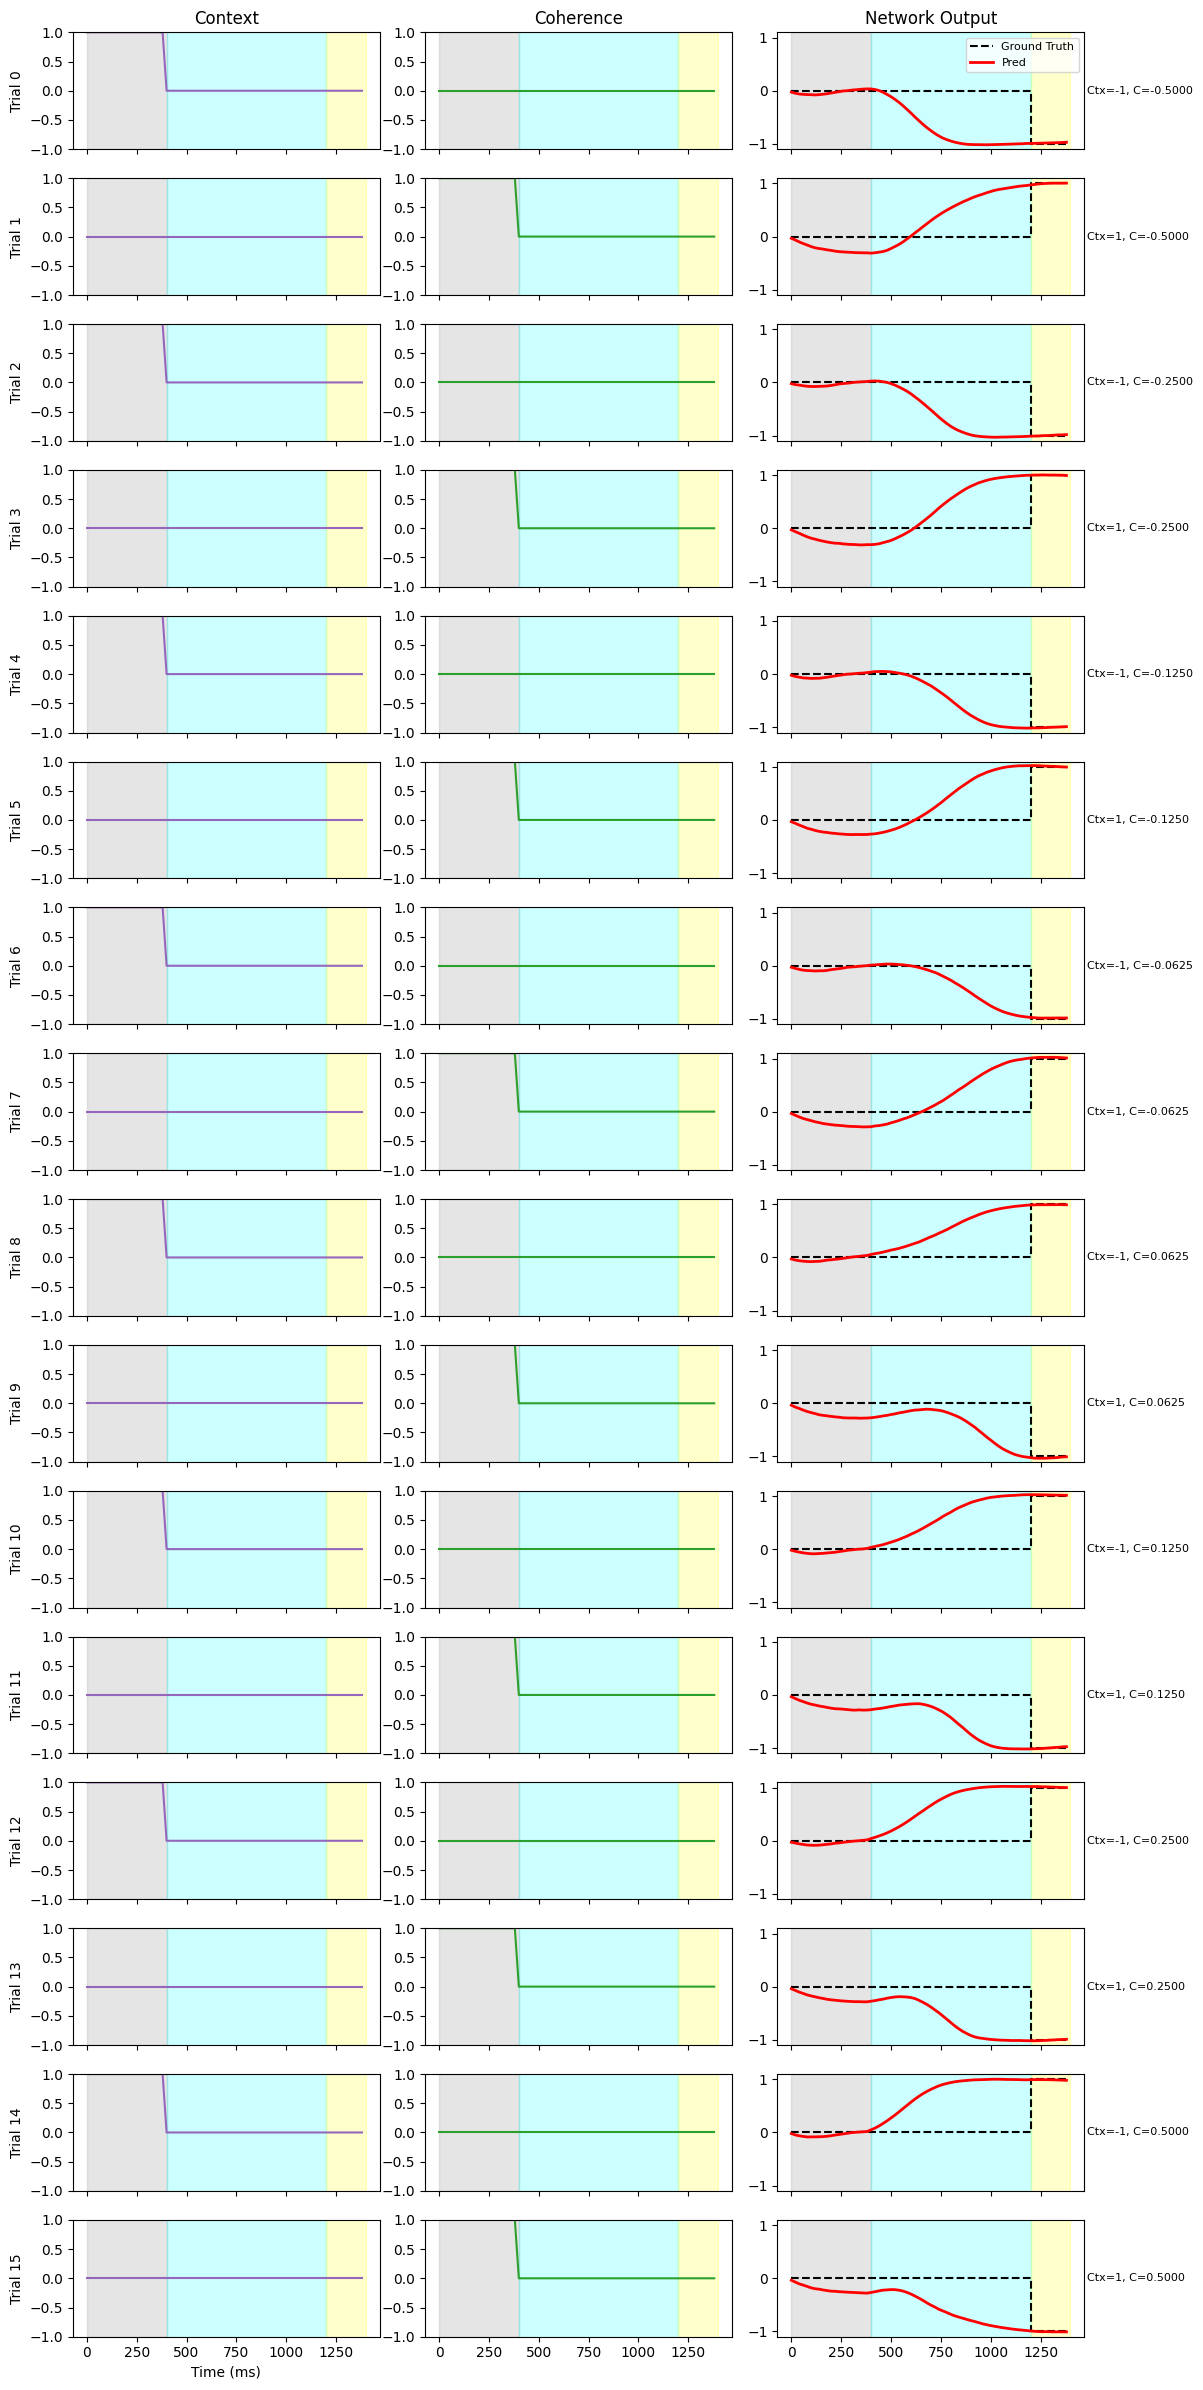

In [7]:


def plot_multiple_xor_pred(X, Y_true, Y_pred, params, trial_indices, deltaT,
                          t_ctx_steps, t_stim_steps, t_total):
    n = len(trial_indices)
    fig, axes = plt.subplots(n, 3, figsize=(12, n * 1.5), sharex=True)
    t = np.arange(t_total) * deltaT
    phases = [
        ('Context', 0, t_ctx_steps, 'gray'),
        ('Stimulus', t_ctx_steps, t_ctx_steps + t_stim_steps, 'cyan'),
        ('Decision', t_ctx_steps + t_stim_steps, t_total, 'yellow')
    ]
    for row, idx in enumerate(trial_indices):
        ctx, coh, _ = params[idx]
        ax_ctx, ax_coh, ax_act = axes[row]
        ax_ctx.plot(t, X[idx, :, 0].numpy(), color='tab:purple')
        ax_ctx.set_ylim(-1, 1)
        if row == 0: ax_ctx.set_title('Context')
        ax_coh.plot(t, X[idx, :, 1].numpy(), color='tab:green')
        ax_coh.set_ylim(-1, 1)
        if row == 0: ax_coh.set_title('Coherence')
        # 画ground truth（黑色虚线）和预测（红色实线）
        ax_act.step(t, Y_true[idx, :, 0].numpy(), where='post', color='k', linestyle='--', label='Ground Truth')
        ax_act.plot(t, Y_pred[idx], color='r', lw=2, label='Pred')
        ax_act.set_ylim(-1.1, 1.1)
        if row == 0: ax_act.set_title('Network Output')
        for ax in (ax_ctx, ax_coh, ax_act):
            for name, start, end, color in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=color, alpha=0.2)
        axes[row, 0].set_ylabel(f'Trial {idx}')
        axes[row, 2].annotate(
            f'Ctx={ctx}, C={coh:.4f}',
            xy=(1.01, 0.5), xycoords='axes fraction',
            va='center', fontsize=8
        )
        if row == 0:
            ax_act.legend(loc='upper right', fontsize=8)
    axes[-1, 0].set_xlabel('Time (ms)')
    plt.tight_layout()
    plt.show()

# 生成16个理想化trial
n_sel = len(coherences) * 2
X_sel = torch.zeros(n_sel, t_total, 3)
Y_sel = torch.zeros(n_sel, t_total, 1)
params_sel = []
idx = 0
for coh in coherences:
    for ctx in [-1, 1]:
        x, y, _ = make_single_xor_trial(ctx, float(coh))
        X_sel[idx] = x
        Y_sel[idx] = y
        params_sel.append((ctx, float(coh), int(y[0, -1, 0])))
        idx += 1

# 网络预测
net.eval()
with torch.no_grad():
    Y_pred = net(X_sel).cpu().numpy()[:, :, 0]

# 可视化
plot_multiple_xor_pred(X_sel, Y_sel, Y_pred, params_sel, list(range(n_sel)),
                       deltaT, t_ctx_steps, t_stim_steps, t_total)

coh -0.5
coh -0.25
coh -0.125
coh -0.0625
coh 0.0625
coh 0.125
coh 0.25
coh 0.5


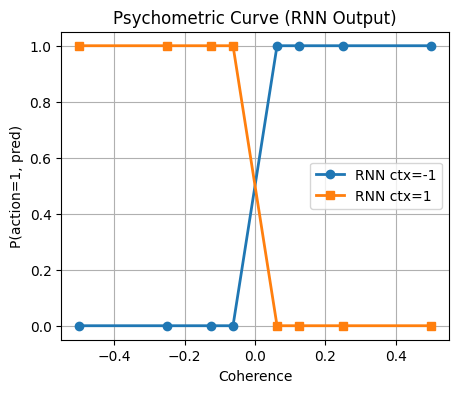

In [8]:

import numpy as np
import matplotlib.pyplot as plt

n_rep = 50  # 每个 (coh, ctx) 重复次数
cohs = np.sort(coherences)
probs_pred_ctx_neg1 = []
probs_pred_ctx1 = []

for coh in cohs:
    # ctx = -1
    outs0 = []
    for _ in range(n_rep):
        x, _, _ = make_single_xor_trial(-1, coh, std=0.05, coh_noise_std=0.05)#常用占位写法，只用到x
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]  # 取决策期最后一帧
        outs0.append(y_pred > 0.5)  # 阈值判定为 action=1
    probs_pred_ctx_neg1.append(np.mean(outs0))

    # ctx = 1
    outs1 = []
    print('coh',coh)
    for _ in range(n_rep):
        x, _, _ = make_single_xor_trial(1, coh, std=0.05,coh_noise_std=0.05)
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]
        outs1.append(y_pred > 0.5)
    probs_pred_ctx1.append(np.mean(outs1))
    
cohs = np.sort(np.array(coherences))
plt.figure(figsize=(5,4))
plt.plot(cohs, probs_pred_ctx_neg1, 'o-', lw=2, label='RNN ctx=-1')
plt.plot(cohs, probs_pred_ctx1, 's-', lw=2, label='RNN ctx=1')
plt.xlabel('Coherence')
plt.ylabel('P(action=1, pred)')
plt.title('Psychometric Curve (RNN Output)')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# Extract parameters from the trained network
W_rec = net.wrec.detach().cpu().numpy()
W_in  = net.wi_full.detach().cpu().numpy()
W_out = net.wo_full.detach().cpu().numpy()
alpha = net.alpha
noise_std = net.noise_std
nonlinearity = np.tanh 

def simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x_seq, h0=None, noise_std=0.0):
    """
    Simulate the RNN dynamics in numpy for analysis.
    x_seq: shape (T, input_dim)
    h0: initial hidden state, shape (hidden_dim,)
    Returns: h_seq (T, hidden_dim), r_seq (T, hidden_dim), y_seq (T, output_dim)
    """
    T, input_dim = x_seq.shape
    hidden_dim = W_rec.shape[0]
    output_dim = W_out.shape[1]
    h_seq = np.zeros((T, hidden_dim))
    r_seq = np.zeros((T, hidden_dim))
    y_seq = np.zeros((T, output_dim))
    h = np.zeros(hidden_dim) if h0 is None else h0.copy()
    for t in range(T):
        noise = np.random.randn(hidden_dim) * noise_std
        r = nonlinearity(h)
        h = h + noise + alpha * (-h + r @ W_rec.T + x_seq[t] @ W_in)
        y = r @ W_out
        h_seq[t] = h
        r_seq[t] = r
        y_seq[t] = y
    return h_seq, r_seq, y_seq


Explained variance ratios: [0.41743907 0.26476428 0.13550712]


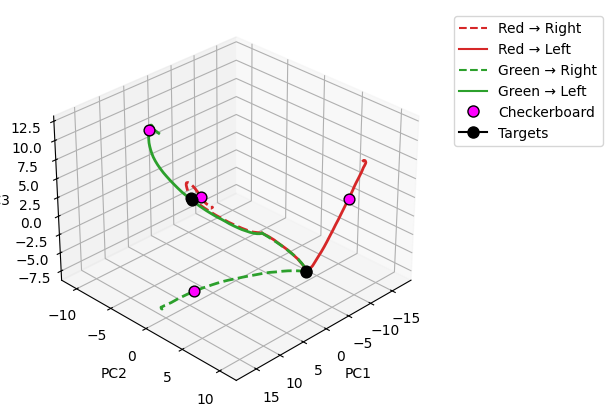

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.lines import Line2D


t_total = t_ctx_steps + t_stim_steps + t_dec_steps


def collect_hidden_trajectories_four_conditions(net, t_total):
    """
    只收集四个典型条件：(ctx, coh) = (-1,0), (-1,1), (1,0), (1,1)
    coh=0.5代表正coherence, coh=-0.5代表负coherence
    返回 all_r, shape = (4, t_total, H)
    """
    W_rec = net.wrec.detach().cpu().numpy()
    W_in  = net.wi_full.detach().cpu().numpy()
    alpha = net.alpha
    noise = net.noise_std

    # 四种典型条件
    conditions = [
        (-1, -0.5),  # ctx=-1, coh=-0.5
        (-1,  0.5),  # ctx=-1, coh=+0.5
        (1, -0.5),  # ctx=1, coh=-0.5
        (1,  0.5),  # ctx=1, coh=+0.5
    ]
    H = W_rec.shape[0]
    all_r = np.zeros((4, t_total, H), dtype=np.float32)
    params = []
    for i, (ctx, coh) in enumerate(conditions):
        x, _, _ = make_single_xor_trial(ctx, coh)
        x_seq = x.squeeze(0).cpu().numpy()
        h = np.zeros(H, dtype=np.float32)
        for t in range(t_total):
            r = np.tanh(h)
            h = h + np.random.randn(H).astype(np.float32) * noise + alpha * (
                -h + W_rec.dot(r) + x_seq[t].dot(W_in)
            )
            all_r[i, t] = r
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]
            action_pred = int(y_pred > 0.5)
        params.append((ctx, coh, action_pred))
    return all_r, params
    return all_r, params

def flatten_trials(all_r):
    """
    展开四个condition的所有时间步，返回 shape=(4*t_total, H)
    """
    N, T, H = all_r.shape
    X = all_r.reshape(N * T, H)
    return X

def run_pca(all_r, n_components=3):
    """
    PCA 降维：all_r (N, T, H) → Z_trials (N, T, 3)
    """
    N, T, H = all_r.shape
    X = flatten_trials(all_r)  # shape: (N*T, H)
    pca = PCA(n_components=n_components)
    Z = pca.fit_transform(X)  # (N*T, n_components)
    print("Explained variance ratios:", pca.explained_variance_ratio_)
    Z_trials = Z.reshape(N, T, n_components)
    return Z_trials, pca

def plot_pca_by_color_action(Z_trials, params,t_total,
                             elev=30, azim=45):#elev 表示视角的仰角（elevation），单位为度，控制上下俯视的角度。azim 表示方位角（azimuth），单位为度，控制左右旋转的角度。
    """
    对四个 (Red/Green × Left/Right) 条件画平均轨迹。
    """
    groups = {('Red','Left'):[],('Red','Right'):[],
              ('Green','Left'):[],('Green','Right'):[]}
    for Z, (ctx, coh, action) in zip(Z_trials, params):#zip(Z_trials, params) 会把每一条 trial 的轨迹 Z 和对应的参数 (ctx, coh, action) 组合在一起，方便在循环中同时处理它们
        color = 'Red'   if coh>0  else 'Green'
        act   = 'Right' if action==1 else 'Left'
        groups[(color,act)].append(Z)#groups 是一个字典，key 是四种条件组合，value 是一个空列表循环中，每条 trial 的降维轨迹 Z 会被 append 到对应条件的列表里。
#所以，groups[(color, act)] 里的每个元素 Z，就是一条 trial 的轨迹（shape 通常为 (T, 3)）。
#最终，groups 的 value（即 v）就是“属于该条件的所有 trial 的轨迹列表

    mean_trajs = {k: np.mean(np.stack(v, axis=0), axis=0)
                  for k, v in groups.items()}#groups.items() 会返回一个可迭代对象，每次迭代返回一个 (k, v) 元组。k 是字典的 key（比如 ('Red', 'Left')）。v 是对应的 value（即该组所有 trial 的轨迹列表

    fig = plt.figure(figsize=(6,6))
    ax  = fig.add_subplot(111, projection='3d')
    style = {
      ('Red','Right'):   ('tab:red','--'),
      ('Red','Left'):    ('tab:red','-'),
      ('Green','Right'): ('tab:green','--'),
      ('Green','Left'):  ('tab:green','-'),
    }

    for key, traj in mean_trajs.items():
        c, ls = style[key]
        ax.plot(traj[:,0], traj[:,1], traj[:,2],
                color=c, linestyle=ls, linewidth=2)
        
        # context input（“Target”）
        p1 = traj[t_ctx_steps]
        ax.scatter(*p1, color='k', s=60, zorder=5)
        # stimulus input（“Checkerboard”）
        p0 = traj[t_stim_steps]
        ax.scatter(*p0, color='magenta', s=60,
                   edgecolor='k', zorder=5)

    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
    legend_elems = [
        Line2D([0],[0], color='tab:red',   ls='--', label='Red → Right'),
        Line2D([0],[0], color='tab:red',   ls='-',  label='Red → Left'),
        Line2D([0],[0], color='tab:green', ls='--', label='Green → Right'),
        Line2D([0],[0], color='tab:green', ls='-',  label='Green → Left'),
        Line2D([0],[0], marker='o', color='w',
               markerfacecolor='magenta', markeredgecolor='k',
               markersize=8, label='Checkerboard'),
        Line2D([0],[0], marker='o', color='k', markersize=8,
               label='Targets'),
    ]
    ax.legend(handles=legend_elems, bbox_to_anchor=(1.05,1), loc='upper left')
    ax.view_init(elev=elev, azim=azim)
    plt.tight_layout()
    plt.show()
# 16 条经典 trial 列表 params_sel
all_r_tuple = collect_hidden_trajectories_four_conditions(net, t_total)
all_r, params = all_r_tuple  # all_r: ndarray, params: list
Z_trials, pca = run_pca(all_r, n_components=3)
plot_pca_by_color_action(Z_trials, params,t_total)


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.lines import Line2D


t_total = t_ctx_steps + t_stim_steps + t_dec_steps


def collect_hidden_trajectories_by_ctx_coh_sign(net, params_sel, t_total):
    """
    收集四种条件（ctx=0/1, coh>0/<0），每种条件下对所有对应coherence trial做平均
    coh>0: coherences中的正值，coh<0: coherences中的负值
    返回 all_r_mean: shape (4, t_total, H), params: [(ctx, coh_sign, action_mean)]
    """
    W_rec = net.wrec.detach().cpu().numpy()
    W_in  = net.wi_full.detach().cpu().numpy()
    alpha = net.alpha
    noise = net.noise_std
    H = W_rec.shape[0]

    # coherences数组
    pos_cohs = [c for c in coherences if c > 0]
    neg_cohs = [c for c in coherences if c < 0]

    conditions = [
        (-1, 'pos'),  # ctx=0, coh>0
        (-1, 'neg'),  # ctx=0, coh<0
        (1, 'pos'),  # ctx=1, coh>0
        (1, 'neg'),  # ctx=1, coh<0
    ]
    all_r_mean = np.zeros((4, t_total, H), dtype=np.float32)
    params_sel = []

    for i, (ctx, sign) in enumerate(conditions):
        # 选取对应coherence集合
        if sign == 'pos':
            coh_set = pos_cohs
        else:
            coh_set = neg_cohs
        # 找到所有对应 trial 索引
        idxs = [j for j, (c, coh, _) in enumerate(params_sel)
                if c == ctx and coh in coh_set]
        r_list = []
        actions = []
        for j in idxs:
            coh = float(params_sel[j][1])#第 j 条 trial 的 coherence
            x, _, _ = make_single_xor_trial(ctx, coh)
            x_seq = x.squeeze(0).cpu().numpy()
            h = np.zeros(H, dtype=np.float32)
            r_traj = np.zeros((t_total, H), dtype=np.float32)
            for t in range(t_total):
                r = np.tanh(h)
                h = h + np.random.randn(H).astype(np.float32) * noise + alpha * (
                    -h + W_rec.dot(r) + x_seq[t].dot(W_in)
                )
                r_traj[t] = r
            r_list.append(r_traj)
            with torch.no_grad():
                y_pred = net(x).cpu().numpy()[0, -1, 0]
                actions.append(int(y_pred > 0.5))
        if len(r_list) > 0:
            all_r_mean[i] = np.mean(np.stack(r_list, axis=0), axis=0)
            action_mean = np.mean(actions)
        else:
            all_r_mean[i] = np.nan
            action_mean = np.nan
        params_sel.append((ctx, sign, action_mean))
    return all_r_mean, params_sel


def flatten_trials(all_r):
    """
    展开四个condition的所有时间步，返回 shape=(4*t_total, H)
    """
    N, T, H = all_r.shape
    X = all_r.reshape(N * T, H)
    return X

def run_pca(all_r, n_components=3):
    """
    PCA 降维：all_r (N, T, H) → Z_trials (N, T, 3)
    """
    N, T, H = all_r.shape
    X = flatten_trials(all_r)  # shape: (N*T, H)
    pca = PCA(n_components=n_components)
    Z = pca.fit_transform(X)  # (N*T, n_components)
    print("Explained variance ratios:", pca.explained_variance_ratio_)
    Z_trials = Z.reshape(N, T, n_components)
    return Z_trials, pca

def plot_pca_by_color_action(Z_trials, params_sel, t_ctx_steps, t_stim_steps, t_total,
                             elev=30, azim=45):
    """
    Z_trials: (4, t_total, 3)
    params_sel: list of 4 tuples (ctx, sign, action_mean)
    t_ctx_steps, t_stim_steps, t_total: ints
    """
    # 先分组
    groups = []
    for Z, (ctx, sign, action) in zip(Z_trials, params_sel):
        # ctx=0 用红；ctx=1 用绿
        stim_ls = '--' if ctx==-1 else '--'
        stim_color = 'tab:red' if ctx==-1 else 'tab:green'
        groups.append((Z, stim_color, stim_ls))
    
    # 四条 decision 段落要用的颜色
    decision_colors = ['tab:blue','tab:orange','tab:purple','tab:cyan']
    
    fig = plt.figure(figsize=(6,6))
    ax  = fig.add_subplot(111, projection='3d')

    for idx, (traj, stim_color, stim_ls) in enumerate(groups):
        k1 = traj[:,0]; k2 = traj[:,1]; k3 = traj[:,2]
        # 分段索引
        t0 = 0
        t1 = t_ctx_steps
        t2 = t_stim_steps
        t3 = t_total

        # 段1：context 阶段（0→t1）灰色实线
        ax.plot(k1[t0:t1+1], k2[t0:t1+1], k3[t0:t1+1],
                color='gray', linestyle='-', linewidth=2)

        # 段2：stimulus 阶段（t1→t2）ctx 决定的红/绿虚线
        ax.plot(k1[t1:t2+1], k2[t1:t2+1], k3[t1:t2+1],
                color=stim_color, linestyle='--', linewidth=2)

        # 段3：decision 阶段（t2→t3）四种不同颜色
        dec_color = decision_colors[idx]
        ax.plot(k1[t2:t3], k2[t2:t3], k3[t2:t3],
                color=dec_color, linestyle='-', linewidth=2)

        # 标记三个关键点：t0, t1, t3-1
        ax.scatter(k1[t0], k2[t0], k3[t0],
                   color='k', s=50, label='Target Onset' if idx==0 else None)
        ax.scatter(k1[t1], k2[t1], k3[t1],
                   color='magenta', s=50, edgecolor='k',
                   label='Checkerboard Onset' if idx==0 else None)
        ax.scatter(k1[t3-1], k2[t3-1], k3[t3-1],
                   color=dec_color, s=50,
                   label='Decision End' if idx==0 else None)

    # 坐标轴标签
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')

    # 构建图例
    legend_elems = [
        Line2D([0],[0], color='gray', linestyle='-',  lw=2, label='Context'),
        Line2D([0],[0], color='tab:red',   ls='--', lw=2, label='Stimulus (ctx=-1)'),
        Line2D([0],[0], color='tab:green', ls='--', lw=2, label='Stimulus (ctx=1)'),
        Line2D([0],[0], color='tab:blue',  lw=2, label='Decision (cond1)'),
        Line2D([0],[0], color='tab:orange',lw=2, label='Decision (cond2)'),
        Line2D([0],[0], color='tab:purple',lw=2, label='Decision (cond3)'),
        Line2D([0],[0], color='tab:cyan',  lw=2, label='Decision (cond4)'),
        Line2D([0],[0], marker='o', color='k', markersize=6, label='Target Onset'),
        Line2D([0],[0], marker='o', color='magenta',
               markeredgecolor='k', markersize=6, label='Checkerboard Onset'),
        Line2D([0],[0], marker='o', color='tab:blue', markersize=6,
               label='Decision End (cond1)'),
    ]
    ax.legend(handles=legend_elems, bbox_to_anchor=(1.05,1), loc='upper left')

    ax.view_init(elev=elev, azim=azim)
    # 添加主标题
    fig.suptitle('Neural State Trajectories in PC Space\n(XOR Task - -1/+1 Onehot)', 
                 fontsize=14, fontweight='bold', y=0.95)
    plt.tight_layout()
    plt.show()


Z_trials, pca = run_pca(all_r, n_components=3)



%matplotlib qt5
plot_pca_by_color_action(Z_trials, params_sel,t_ctx_steps, t_stim_steps, t_total)


Explained variance ratios: [0.41743943 0.26476416 0.13550717]


In [25]:


# 提取每个PC上的四条轨迹
pc1_trajs = Z_trials[:, :, 0]  # shape: (4, t_total)
pc2_trajs = Z_trials[:, :, 1]  # shape: (4, t_total)
pc3_trajs = Z_trials[:, :, 2]  # shape: (4, t_total)

# 可选：画出每个PC上的四条轨迹
import matplotlib.pyplot as plt

pcs = [pc1_trajs, pc2_trajs, pc3_trajs]
pc_names = ['PC1', 'PC2', 'PC3']
condition_labels = [f'ctx={ctx}, coh={coh}' for ctx, coh, _ in params]

for i, pc_trajs in enumerate(pcs):
    plt.figure(figsize=(8, 3))
    for j in range(4):
        plt.plot(pc_trajs[j], label=condition_labels[j])
    plt.title(f'Four Trajectories on {pc_names[i]}')
    plt.xlabel('Time step')
    plt.ylabel(pc_names[i])
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# def velocity_field_with_input(hidden_init, Umat, x_t,pca_remains,n_grid):
#     """
#     计算给定输入 x_t 时，PC1–PC2 平面上的速度场。
#     - pts3: (M,3) 低维点
#     - x_t:   (2,)  输入向量 [context, coherence] at time t
#     返回：
#     - U: shape (n_grid,n_grid) 对应 PC1 分量
#     - V: shape (n_grid,n_grid) 对应 PC2 分量
#     """
#     velocity = np.zeros((np.shape(hidden_init)[0], 2))
#     for i in range(np.shape(hidden_init)[0]):
#         init_pc12 = np.squeeze(hidden_init[i,:])
#         pts_merge = np.concatenate((init_pc12, pca_remains), axis=0)
#         # 1) 重建高维隐藏态 h
#         ##@YS ??? 
#         r = pts_merge.dot(Umat)           # Umat shape: (280, 512)
#         if np.abs(r).max() > 1:
#             r = np.clip(r, -0.999, 0.999)
#         h = np.arctanh(r)
#         # h = pts_merge.dot(Umat)  #(M,H)
#         # r = np.tanh(h)                # (M,H)
        
#         # 2) 计算 dh = -h + W_rec·r + W_in·x_t
#         #    W_rec·r^T = r.dot(W_rec.T)
    #     #    W_in·x_t = x_t.dot(W_in)  gives (H,)
    #     dh = -h + r.dot(W_rec.T) + x_t.dot(W_in)
    #     # 3) Euler 步长
    #     h_new = h + alpha * dh
    #     r_new = np.tanh(h_new)
    #     # 4) 活动速度 dr = r_new - r
    #     dr = r_new - r           
    #     # 5) 投影到 PCA 空间： 
    #     v_pc = dr.dot(Umat.T)        #Umat：等同于 pca.components_，shape (n_components, H)，它的第 k 行就是第 k 个主成分在 H 维空间里的方向向量。
    #     velocity[i, :] = v_pc[:2]    #把 PC1 和 PC2 的变化率（速度）提取出来，用于在平面里画箭头。
    # # 拆出 PC1, PC2 分量并 reshape
    # U = velocity[:,0].reshape(n_grid,n_grid)
    # V = velocity[:,1].reshape(n_grid,n_grid)
    # # velocity = v_pc[:, :2].reshape(n_grid, n_grid, 2).transpose(2,0,1)
    # return U, V

In [12]:
def velocity_field_with_input(hidden_init, Umat, x_t,pca_remains,n_grid):
    """
    计算给定输入 x_t 时，PC1–PC2 平面上的速度场。
    - pts3: (M,3) 低维点
    - x_t:   (2,)  输入向量 [context, coherence] at time t
    返回：
    - U: shape (n_grid,n_grid) 对应 PC1 分量
    - V: shape (n_grid,n_grid) 对应 PC2 分量
    """
    velocity = np.zeros((np.shape(hidden_init)[0], 2))
    for i in range(np.shape(hidden_init)[0]):
        init_pc12 = np.squeeze(hidden_init[i,:])# 提取第i个网格点的PC1和PC2坐标
# init_pc12 shape: (2,) - [PC1_value, PC2_value]
        pts_merge = np.concatenate((init_pc12, pca_remains), axis=0)# init_pc12: (2,) - PC1, PC2坐标 
# pca_remains: (278,) - PC3到PC280的坐标
# pts_merge: (280,) - 完整的PCA坐标向量

        # 1) 重建高维隐藏态 h
        ##@YS ??? 
        r = pts_merge.dot(Umat)            # (M,H)
        if np.abs(r).max() > 1:
            r = np.clip(r, -0.999, 0.999)
        h = np.arctanh(r)
        # h = pts_merge.dot(Umat)  #(M,H)
        # r = np.tanh(h)                # (M,H)
        
        # 2) 计算 dh = -h + W_rec·r + W_in·x_t
        #    W_rec·r^T = r.dot(W_rec.T)
        #    W_in·x_t = x_t.dot(W_in)  gives (H,)
        dh = -h + r.dot(W_rec.T) + x_t.dot(W_in)
        # 3) Euler 步长
        h_new = h + alpha * dh
        r_new = np.tanh(h_new)
        # 4) 活动速度 dr = r_new - r
        dr = r_new - r               # (M,H)
        # 5) 投影到 PCA 空间： dr·Umat^T → (M,3)
        v_pc = dr.dot(Umat.T)        # (M,3)
        velocity[i, :] = v_pc[:2]
    # 拆出 PC1, PC2 分量并 reshape
    U = velocity[:,0].reshape(n_grid,n_grid)
    V = velocity[:,1].reshape(n_grid,n_grid)
    # velocity = v_pc[:, :2].reshape(n_grid, n_grid, 2).transpose(2,0,1)
    return U, V

In [ ]:
# _, pca_full= run_pca(all_r, n_components=280)


Explained variance ratios: [4.8448595e-01 1.9439562e-01 1.2875615e-01 8.0235876e-02 4.8034679e-02
 2.3244468e-02 1.3963270e-02 9.8776780e-03 5.3077415e-03 2.8490748e-03
 1.8789237e-03 1.1705988e-03 1.0908684e-03 8.9399167e-04 7.0013234e-04
 5.4509111e-04 3.4903322e-04 2.8628024e-04 2.5194883e-04 2.4626215e-04
 1.4008001e-04 1.3218749e-04 1.0841074e-04 1.0248779e-04 9.2482980e-05
 8.7776352e-05 7.5385178e-05 6.1399551e-05 4.8144153e-05 4.2654465e-05
 3.7113321e-05 3.4655299e-05 3.3528082e-05 2.7670376e-05 2.4486642e-05
 1.8571402e-05 1.6176495e-05 1.5318969e-05 1.3930101e-05 1.3776936e-05
 1.3285742e-05 1.2029330e-05 9.9820063e-06 9.4275611e-06 9.2745850e-06
 8.6201690e-06 8.1038406e-06 7.8182293e-06 7.1510440e-06 6.9784596e-06
 6.5828731e-06 6.2144959e-06 5.7965190e-06 5.3324716e-06 5.1908301e-06
 5.0525146e-06 4.7457665e-06 4.5855572e-06 4.3313089e-06 4.1907329e-06
 3.9232400e-06 3.8970629e-06 3.6442459e-06 3.5162443e-06 3.4300224e-06
 3.3711990e-06 3.2511819e-06 3.1220009e-06 2.92134

In [13]:
_, pca_full= run_pca(all_r, n_components=280)
conds = [(-1, 0.5), (-1, -0.5),(1,-0.5),(-1,0.5)]
x_seqs = []
for ctx, coh in conds:
    x, _, _ = make_single_xor_trial(ctx, coh, std=0.0,coh_noise_std=0.0)
    x_seqs.append(x.squeeze(0).cpu().numpy())
    h0, r0, y0 = simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x_seqs[0], h0=None, noise_std=0.0)
    r0_pca = pca_full.transform(r0)  # (t_total, 3)

r0_pca = pca.transform(r0)  # (1, 3)
init_pc12 = np.array([r0_pca[0, 0], r0_pca[0, 1]])
pca_remains = r0_pca[0,2:]
pca_merge = np.concatenate((init_pc12, pca_remains), axis=0)
r0_pca[t_total-1,2]

Explained variance ratios: [4.17439371e-01 2.64764458e-01 1.35507166e-01 7.60846213e-02
 5.03388792e-02 2.07593068e-02 1.20332483e-02 8.30509048e-03
 4.91833035e-03 2.09033885e-03 1.63135945e-03 1.21145230e-03
 7.81294890e-04 7.51375512e-04 6.87965308e-04 5.44501818e-04
 2.59355322e-04 2.49674253e-04 2.25738084e-04 1.53330213e-04
 1.29767664e-04 1.24370374e-04 1.01703896e-04 9.84603175e-05
 7.90380436e-05 5.94922822e-05 5.28151359e-05 4.84614975e-05
 4.27235136e-05 3.77552315e-05 3.48165559e-05 3.05693466e-05
 2.63177535e-05 2.13578205e-05 1.94848999e-05 1.61988810e-05
 1.56181650e-05 1.47557184e-05 1.26216082e-05 1.07518326e-05
 1.06974558e-05 9.35108710e-06 8.78583432e-06 8.22248057e-06
 7.83172800e-06 7.31636828e-06 6.82291602e-06 6.56134398e-06
 6.40025473e-06 5.86578972e-06 5.79807238e-06 5.65929031e-06
 5.50101595e-06 5.25014866e-06 4.73470072e-06 4.62863500e-06
 4.54799010e-06 4.25510598e-06 4.16828379e-06 4.06419667e-06
 3.87266527e-06 3.67584721e-06 3.53490873e-06 3.45483613e-

np.float64(-6.219209868803981)

In [18]:
import numpy as np
import matplotlib.pyplot as plt

t_total = t_ctx_steps + t_stim_steps + t_dec_steps
alpha   = 0.1  # dt/tau

# 1) 构建 PC1–PC2 平面网格
all_k1 = Z_trials[:,:,0].ravel()
all_k2 = Z_trials[:,:,1].ravel()
k1_min, k1_max = -15,15
k2_min, k2_max = -15,15

n_grid = 25
xx, yy = np.meshgrid(
    np.linspace(k1_min, k1_max, n_grid),
    np.linspace(k2_min, k2_max, n_grid)
)
hidden_grid_2d = np.vstack((xx.flatten(),  yy.flatten())).T
hidden_init = np.zeros((hidden_grid_2d.shape[0], 2))
hidden_init[:,:] = hidden_grid_2d

# 提取网络权重和 PCA 基
W_rec = net.wrec.detach().cpu().numpy()
W_in  = net.wi_full.detach().cpu().numpy()   # shape (2, H)
Umat  = pca_full.components_                     # shape (3, H)
W_out = net.wo_full.detach().cpu().numpy()
alpha = net.alpha
noise_std = net.noise_std
nonlinearity = np.tanh 

# 2) 生成四个 trial 的输入序列
conds = [(-1, -0.5), (-1, 0.5), (1, -0.5), (1, 0.5)]
x_seqs = []
rpca_seqs = []
for ctx, coh in conds:
    x, _, _ = make_single_xor_trial(ctx, coh, std=0.0,coh_noise_std=0.0)
    x0 = x.squeeze(0).cpu().numpy()  # shape (t_total, 2)
    x_seqs.append(x0)  # shape (t_total, 2)
    h0, r0, y0 = simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x0, h0=None, noise_std=0.0)
    r0_pca = pca_full.transform(r0) 
    rpca_seqs.append(r0_pca)  # shape (t_total, 3)

init_pc12 = np.array([r0_pca[0, 0], r0_pca[0, 1]])
pca_remains = r0_pca[0,2:]
pca_merge = np.concatenate((init_pc12, pca_remains), axis=0)


# 3) 绘制 2×2 子图
fig, axes = plt.subplots(2,2, figsize=(10,10), sharex=True, sharey=True)
titles = ['Config1 coh<0','Config1 coh>0','Config2 coh<0','Config2 coh>0']
coh_color = { -0.5: 'tab:red', 0.5: 'tab:green' }

for ax, idx, title in zip(axes.ravel(), range(4), titles):
    # 3.1 选择 t1=0 (Target Onset)、t2=t_ctx_steps (Checkerboard Onset)
    #     并构造速度场在 Checkerb
    x_t = x_seqs[idx][t_stim_steps]         # 输入 at checkerboard onset
    pc3 = rpca_seqs[idx][t_stim_steps,2:]    # PC3 at checkerboard onset
    # print(pc3,'-------')
    U, V = velocity_field_with_input(hidden_init, Umat, x_t,pc3,n_grid)
    
    # 背景速度幅值
    speed = np.sqrt(U**2 + V**2)
    pcm = ax.pcolormesh(xx, yy, speed, shading='auto', cmap='plasma')
    ax.streamplot(xx, yy, U, V, color='white', density=1.0, linewidth=0.6)
    
    # 4) 三段平均轨迹
    traj = Z_trials[idx]  # (t_total, 3)
    k1 = traj[:,0]; k2 = traj[:,1]
    # 段索引
    t0 = 0
    t1 = t_ctx_steps
    t2 = t_ctx_steps + t_stim_steps
    t3 = t_total

    color = coh_color[conds[idx][1]]
    # 段1：context only
    ax.plot(k1[t0:t1+1], k2[t0:t1+1], color='gray', linewidth=2)
    # 段2：stimulus
    ax.plot(k1[t1:t2+1], k2[t1:t2+1], color=color, linewidth=2)
    # 段3：decision
    ax.plot(k1[t2:t3],    k2[t2:t3],    color=color, linestyle='--', linewidth=2)

    # 标记两点
    ax.scatter(k1[t0], k2[t0], color='k',   s=60, label='Target Onset')
    ax.scatter(k1[t1], k2[t1], color='tab:red', s=60, edgecolor='k', label='Checkerboard Onset')
    
    ax.set_title(title)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')

# colorbar & legend
# fig.colorbar(pcm, ax=axes.ravel().tolist(), label='Activity velocity in PC space')
axes[0,0].legend(loc='upper right')
plt.suptitle('Fig. 2D – Velocity & 3‑segment Trajectories -1/+1 checkerboard onset', y=0.93)
plt.tight_layout()
plt.show()
